# Logistic Regression on Advertising Dataset

## Business Analysis Internship - Major Project

### Organization:
**EdiGlobe**

### Prepared By:
**Arhan Shaikh**

### Algorithm Used:
**Logistic Regression**

### Programming Language:
**Python**

### Libraries Used:
Pandas, NumPy, Matplotlib, Seaborn, Scikit-Learn

---

## Project Objective:

To develop a Logistic Regression model capable of predicting whether a user will click on an online advertisement using demographic and behavioural attributes. The project applies data analysis, visualization, feature engineering and machine learning techniques to generate actionable business insights.

---

# Executive Summary

This project develops a Logistic Regression model to predict whether a user will click on an online advertisement. The workflow includes data exploration, visualization, feature selection, feature scaling, model training and performance evaluation.

The final model achieved an overall accuracy of **96%**, demonstrating excellent predictive capability. The analysis indicates that behavioural variables such as Daily Internet Usage and Daily Time Spent on Site have a stronger influence on advertisement clicks than demographic variables.

The developed model can assist businesses in improving advertisement targeting, enhancing customer engagement and supporting data-driven marketing decisions.

---

## Brief Note on Logistic Regression

Logistic Regression is a supervised machine learning algorithm used for binary classification problems, where the target variable has only two possible outcomes, such as Yes/No, True/False, or 0/1. Instead of predicting continuous values, it estimates the probability that an observation belongs to a particular class.

The algorithm uses the Sigmoid Function to convert a linear combination of input features into a probability value ranging from 0 to 1. Based on a predefined threshold (typically 0.5), the probability is classified into one of the two target classes. Due to its simplicity, interpretability, and efficiency, Logistic Regression is widely used in domains such as marketing, banking, healthcare, fraud detection, and customer behaviour analysis.

In this project, Logistic Regression is used to predict whether a user is likely to click on an online advertisement based on demographic and behavioural characteristics such as age, daily time spent on the website, area income, daily internet usage, and gender.

---

In [102]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 

In [103]:
df = pd.read_csv("advertising.csv")

In [104]:
df

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Ad Topic Line,City,Male,Country,Timestamp,Clicked on Ad
0,68.95,35,61833.90,256.09,Cloned 5thgeneration orchestration,Wrightburgh,0,Tunisia,27-03-2016 00:53,0
1,80.23,31,68441.85,193.77,Monitored national standardization,West Jodi,1,Nauru,04-04-2016 01:39,0
2,69.47,26,59785.94,236.50,Organic bottom-line service-desk,Davidton,0,San Marino,13-03-2016 20:35,0
3,74.15,29,54806.18,245.89,Triple-buffered reciprocal time-frame,West Terrifurt,1,Italy,10-01-2016 02:31,0
4,68.37,35,73889.99,225.58,Robust logistical utilization,South Manuel,0,Iceland,03-06-2016 03:36,0
...,...,...,...,...,...,...,...,...,...,...
995,72.97,30,71384.57,208.58,Fundamental modular algorithm,Duffystad,1,Lebanon,11-02-2016 21:49,1
996,51.30,45,67782.17,134.42,Grass-roots cohesive monitoring,New Darlene,1,Bosnia and Herzegovina,22-04-2016 02:07,1
997,51.63,51,42415.72,120.37,Expanded intangible solution,South Jessica,1,Mongolia,01-02-2016 17:24,1
998,55.55,19,41920.79,187.95,Proactive bandwidth-monitored policy,West Steven,0,Guatemala,24-03-2016 02:35,0


In [105]:
df.info

<bound method DataFrame.info of      Daily Time Spent on Site  Age  Area Income  Daily Internet Usage  \
0                       68.95   35     61833.90                256.09   
1                       80.23   31     68441.85                193.77   
2                       69.47   26     59785.94                236.50   
3                       74.15   29     54806.18                245.89   
4                       68.37   35     73889.99                225.58   
..                        ...  ...          ...                   ...   
995                     72.97   30     71384.57                208.58   
996                     51.30   45     67782.17                134.42   
997                     51.63   51     42415.72                120.37   
998                     55.55   19     41920.79                187.95   
999                     45.01   26     29875.80                178.35   

                             Ad Topic Line            City  Male  \
0       Cloned 5thgener

In [106]:
display(df.head())

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Ad Topic Line,City,Male,Country,Timestamp,Clicked on Ad
0,68.95,35,61833.90,256.09,Cloned 5thgeneration orchestration,Wrightburgh,0,Tunisia,27-03-2016 00:53,0
1,80.23,31,68441.85,193.77,Monitored national standardization,West Jodi,1,Nauru,04-04-2016 01:39,0
2,69.47,26,59785.94,236.50,Organic bottom-line service-desk,Davidton,0,San Marino,13-03-2016 20:35,0
3,74.15,29,54806.18,245.89,Triple-buffered reciprocal time-frame,West Terrifurt,1,Italy,10-01-2016 02:31,0
4,68.37,35,73889.99,225.58,Robust logistical utilization,South Manuel,0,Iceland,03-06-2016 03:36,0


In [107]:
df.describe()

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Male,Clicked on Ad
count,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00
mean,65.00,36.01,55000.00,180.00,0.48,0.50
std,15.85,8.79,13414.63,43.90,0.50,0.50
min,32.60,19.00,13996.50,104.78,0.00,0.00
25%,51.36,29.00,47031.80,138.83,0.00,0.00
50%,68.22,35.00,57012.30,183.13,0.00,0.50
75%,78.55,42.00,65470.63,218.79,1.00,1.00
max,91.43,61.00,79484.80,269.96,1.00,1.00


In [108]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 10)
pd.set_option('display.float_format', '{:.2f}'.format)

In [109]:
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10,6)

In [110]:
df.shape

(1000, 10)

In [111]:
df.head()

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Ad Topic Line,City,Male,Country,Timestamp,Clicked on Ad
0,68.95,35,61833.90,256.09,Cloned 5thgeneration orchestration,Wrightburgh,0,Tunisia,27-03-2016 00:53,0
1,80.23,31,68441.85,193.77,Monitored national standardization,West Jodi,1,Nauru,04-04-2016 01:39,0
2,69.47,26,59785.94,236.50,Organic bottom-line service-desk,Davidton,0,San Marino,13-03-2016 20:35,0
3,74.15,29,54806.18,245.89,Triple-buffered reciprocal time-frame,West Terrifurt,1,Italy,10-01-2016 02:31,0
4,68.37,35,73889.99,225.58,Robust logistical utilization,South Manuel,0,Iceland,03-06-2016 03:36,0


In [112]:
display(df.tail())

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Ad Topic Line,City,Male,Country,Timestamp,Clicked on Ad
995,72.97,30,71384.57,208.58,Fundamental modular algorithm,Duffystad,1,Lebanon,11-02-2016 21:49,1
996,51.30,45,67782.17,134.42,Grass-roots cohesive monitoring,New Darlene,1,Bosnia and Herzegovina,22-04-2016 02:07,1
997,51.63,51,42415.72,120.37,Expanded intangible solution,South Jessica,1,Mongolia,01-02-2016 17:24,1
998,55.55,19,41920.79,187.95,Proactive bandwidth-monitored policy,West Steven,0,Guatemala,24-03-2016 02:35,0
999,45.01,26,29875.80,178.35,Virtual 5thgeneration emulation,Ronniemouth,0,Brazil,03-06-2016 21:43,1


---

# 1. Exploratory Data Analysis - (EDA)

EDA helps us understand the structure, distribution, and relationships within the dataset before developing a machine learning model.

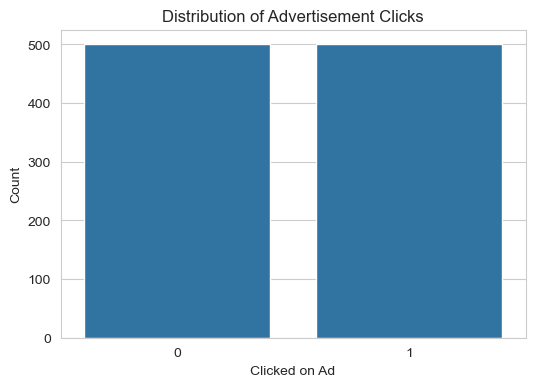

In [113]:
plt.figure(figsize=(6,4))

sns.countplot(x='Clicked on Ad', data=df)

plt.title("Distribution of Advertisement Clicks")
plt.xlabel("Clicked on Ad")
plt.ylabel("Count")

plt.show()

### Observation

The target variable appears to be well balanced, indicating that the dataset contains a similar number of users who clicked and did not click on the advertisement. A balanced dataset generally improves the reliability of machine learning models.

---

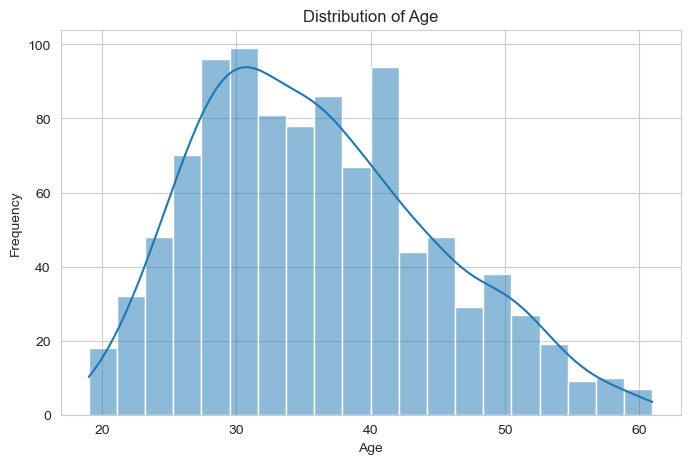

In [114]:
plt.figure(figsize=(8,5))

sns.histplot(df['Age'], bins=20, kde=True)

plt.title("Distribution of Age")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

### Observation

Most users belong to the young and middle-aged population. The age distribution appears approximately normal, suggesting a diverse customer base without extreme age concentrations.

---

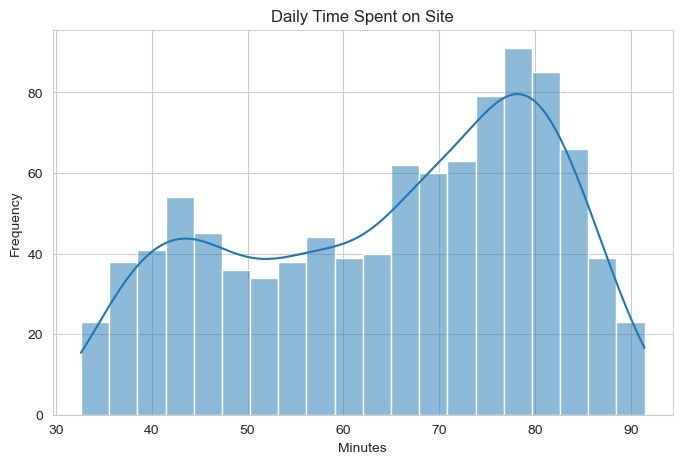

In [115]:
plt.figure(figsize=(8,5))

sns.histplot(df['Daily Time Spent on Site'], bins=20, kde=True)

plt.title("Daily Time Spent on Site")
plt.xlabel("Minutes")
plt.ylabel("Frequency")

plt.show()

### Observation:

The distribution of daily time spent on the website is concentrated between 70 and 85 minutes, indicating that a large proportion of users spend a considerable amount of time on the site. There are relatively fewer users with very low or very high browsing times.

### Business Insight:

Higher time spent on the website suggests stronger user engagement, which may increase the likelihood of users interacting with or clicking on advertisements.

---

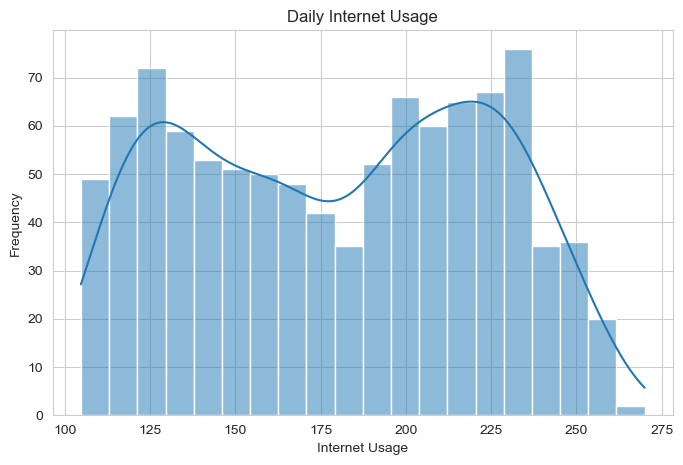

In [116]:
plt.figure(figsize=(8,5))

sns.histplot(df['Daily Internet Usage'], bins=20, kde=True)

plt.title("Daily Internet Usage")

plt.xlabel("Internet Usage")

plt.ylabel("Frequency")

plt.show()

### Observation:

The distribution of daily internet usage ranges from approximately 100 to 270 minutes, with a higher concentration of users between 200 and 240 minutes. This indicates that a significant portion of users spend considerable time on the internet each day.

### Business Insight:

Users with higher daily internet usage are generally more active online, making them a valuable target audience for digital advertising campaigns and potentially more likely to engage with online advertisements.

---

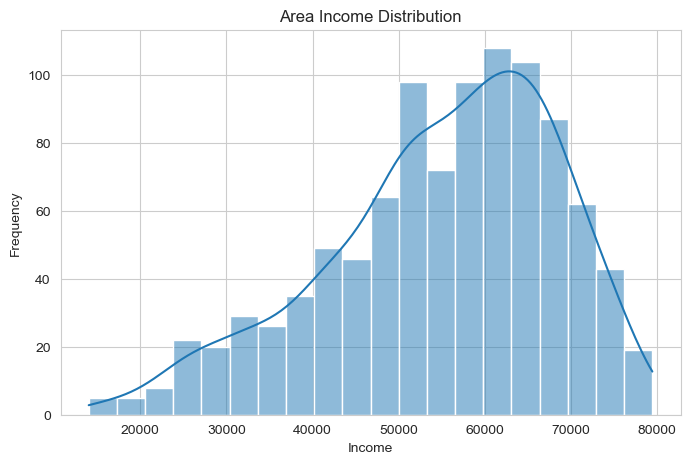

In [117]:
plt.figure(figsize=(8,5))

sns.histplot(df['Area Income'], bins=20, kde=True)

plt.title("Area Income Distribution")

plt.xlabel("Income")

plt.ylabel("Frequency")

plt.show()

### Observation:

The area income is primarily concentrated between ₹50,000 and ₹70,000, with the highest frequency around ₹60,000–₹65,000. This indicates that most users belong to the middle- to upper-income group.

### Business Insight:

Understanding the income distribution helps businesses design targeted advertising campaigns and recommend products or services that align with the purchasing power of their primary audience.

---

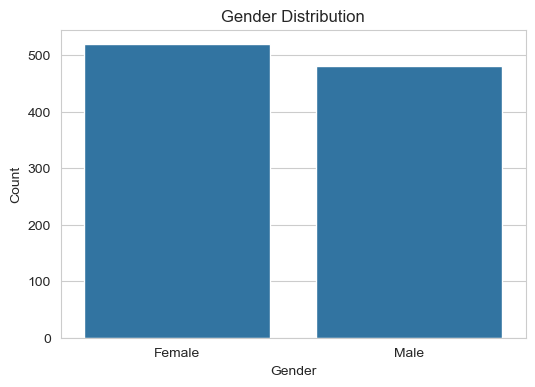

In [118]:
plt.figure(figsize=(6,4))

sns.countplot(x='Male', data=df)

plt.title("Gender Distribution")
plt.xticks([0, 1], ["Female", "Male"])
plt.xlabel("Gender")
plt.ylabel("Count")

plt.show()

### Observation

The dataset contains a nearly balanced distribution of female and male users, with female users slightly outnumbering male users. This balanced representation helps ensure fair and unbiased model training.

---

# 2. Correlation Heatmap

A correlation heatmap helps identify relationships between numerical variables in the dataset. It enables us to understand which features are strongly associated with one another and with the target variable before building the machine learning model.

In [119]:
numerical_df = df.select_dtypes(include=['number'])

In [120]:
numerical_df.head()

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Male,Clicked on Ad
0,68.95,35,61833.90,256.09,0,0
1,80.23,31,68441.85,193.77,1,0
2,69.47,26,59785.94,236.50,0,0
3,74.15,29,54806.18,245.89,1,0
4,68.37,35,73889.99,225.58,0,0


In [121]:
correlation = numerical_df.corr()

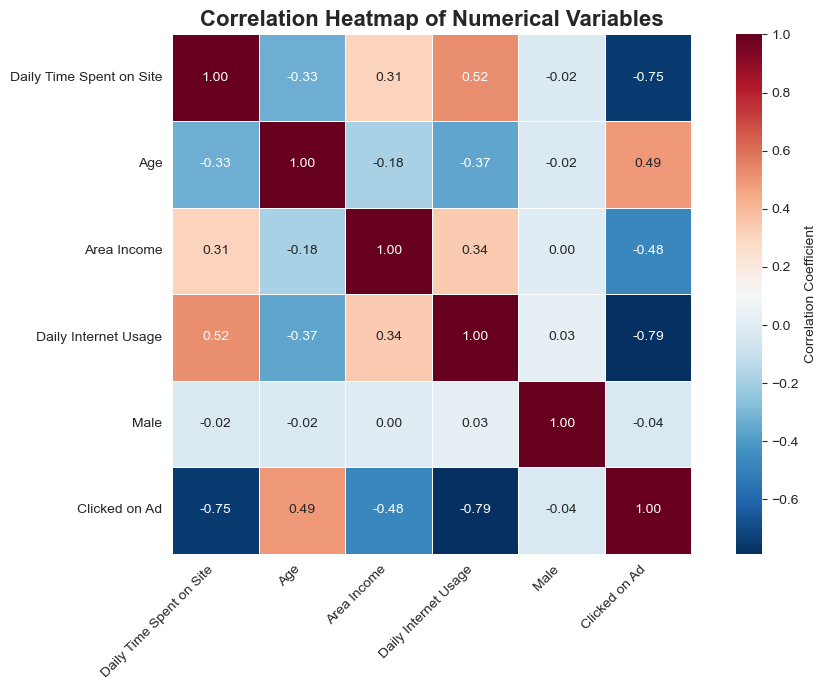

In [122]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="RdBu_r",
    fmt=".2f",
    linewidths=0.5,
    square=True,
    cbar_kws={"label": "Correlation Coefficient"}
)

plt.title("Correlation Heatmap of Numerical Variables", fontsize=16, fontweight="bold")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

### Observations

The correlation heatmap indicates that Daily Internet Usage (-0.79) and Daily Time Spent on Site (-0.75) exhibit the strongest relationships with the target variable (Clicked on Ad), suggesting that these features are likely to have the greatest influence on advertisement click behavior. In contrast, the Male variable shows a negligible correlation (-0.04), indicating that gender has little impact on whether a user clicks an advertisement.

Additionally, no pair of independent variables exhibits an extremely high correlation (close to ±1), suggesting the absence of significant multicollinearity. This is beneficial, as it allows the Logistic Regression model to learn from each feature without substantial redundancy.

### Business Insights 

The analysis suggests that user engagement metrics, such as the time spent on the website and daily internet usage, are stronger predictors of advertisement clicks than demographic factors like gender. This indicates that businesses should prioritize customer behavior when designing targeted advertising strategies.

Furthermore, since the predictor variables are not highly correlated with one another, each feature contributes unique information to the model. This is expected to improve the reliability and interpretability of the Logistic Regression model, leading to more accurate predictions and better-informed marketing decisions.

---

# 3. Sigmoid Function 

The Sigmoid Function is the core mathematical function used in Logistic Regression. It converts any real-valued input into a probability between 0 and 1, allowing the model to classify observations into two categories.

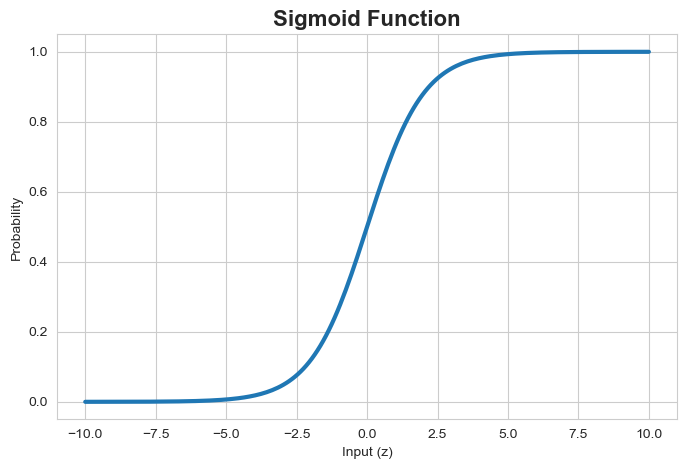

In [123]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-10, 10, 200)

y = 1 / (1 + np.exp(-x))

plt.figure(figsize=(8,5))

plt.plot(x, y, linewidth=3)

plt.title("Sigmoid Function", fontsize=16, fontweight="bold")
plt.xlabel("Input (z)")
plt.ylabel("Probability")

plt.grid(True)

plt.show()

### Observation

The Sigmoid Function produces a smooth S-shaped curve that maps every real-valued input to a probability between 0 and 1. As the input value increases, the predicted probability gradually rises from near 0 to near 1, with the probability reaching 0.5 when the input is 0.

### Business Insights

The Sigmoid Function enables the Logistic Regression model to estimate the probability of a user clicking on an advertisement rather than making a direct yes/no prediction. This probability-based approach allows businesses to identify high-potential customers and make more informed, data-driven marketing decisions.

---

# 4. Feature Selection

Feature selection is the process of identifying the independent variables (features) that will be used to predict the target variable. Only relevant numerical features are selected for building the Logistic Regression model.

In [124]:
X = df[['Daily Time Spent on Site',
        'Age',
        'Area Income',
        'Daily Internet Usage',
        'Male']]

In [125]:
X.head()

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Male
0,68.95,35,61833.90,256.09,0
1,80.23,31,68441.85,193.77,1
2,69.47,26,59785.94,236.50,0
3,74.15,29,54806.18,245.89,1
4,68.37,35,73889.99,225.58,0


In [126]:
y = df['Clicked on Ad']

In [127]:
y.head()

0    0
1    0
2    0
3    0
4    0
Name: Clicked on Ad, dtype: int64

In [128]:
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (1000, 5)
Target Shape: (1000,)


### NOTE:

Selecting only relevant numerical features simplifies the model while retaining the most informative variables for predicting advertisement clicks. Removing unnecessary text-based attributes reduces complexity and improves model efficiency.

Five numerical features were selected as independent variables, while Clicked on Ad was chosen as the dependent variable. This prepares the dataset for training the Logistic Regression model using relevant customer information.

In [129]:
X = df[['Daily Time Spent on Site',
        'Age',
        'Area Income',
        'Daily Internet Usage',
        'Male']]

y = df['Clicked on Ad']

X.head()

y.head()

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (1000, 5)
Target Shape: (1000,)


---

# 5. Train - Test Split

The dataset is divided into training and testing sets. The training data is used to build the Logistic Regression model, while the testing data is used to evaluate its performance on unseen observations.

In [130]:
from sklearn.model_selection import train_test_split

In [131]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [132]:
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (800, 5)
Testing Features: (200, 5)
Training Target: (800,)
Testing Target: (200,)


### NOTE:

Splitting the dataset ensures that the model is evaluated on unseen data, providing a realistic measure of its predictive performance. This helps businesses assess how well the model is likely to perform when making predictions for future customers.

The dataset was divided into 80% training data and 20% testing data, resulting in 800 training observations and 200 testing observations. This approach enables reliable model training while preserving unseen data for performance evaluation.

In [133]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (800, 5)
Testing Features: (200, 5)
Training Target: (800,)
Testing Target: (200,)


---

# 6. Feature Scaling 

Feature scaling standardizes the numerical features so that they have a similar scale. This improves the efficiency of the Logistic Regression algorithm and helps the optimization process converge more effectively.

In [134]:
from sklearn.preprocessing import StandardScaler

In [135]:
scaler = StandardScaler()

In [136]:
X_train_scaled = scaler.fit_transform(X_train)

In [137]:
X_test_scaled = scaler.transform(X_test)

---

# 7. Building the Logistic Regression Model

A Logistic Regression model is trained using the training dataset. During training, the model learns the relationship between customer characteristics and advertisement click behaviour.

In [138]:
model = LogisticRegression(max_iter=1000)

In [139]:
model.fit(X_train_scaled, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [140]:
y_pred = model.predict(X_test_scaled)

In [141]:
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

comparison.index = comparison.index + 1

comparison.head(10)

,Actual,Predicted
1,1,1
2,1,1
3,1,1
4,1,1
5,0,0
6,0,0
7,0,0
8,1,1
9,0,0
10,1,1


## NOTE:

The numerical features were standardized using the StandardScaler technique before training the Logistic Regression model. Feature scaling ensures that all variables contribute proportionately to the model and improves the convergence of the optimization algorithm.

Standardizing the input features improves the stability and efficiency of the Logistic Regression model, resulting in more reliable predictions. This enables businesses to make better decisions based on consistent model performance across variables with different measurement scales.

In [142]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

In [143]:
accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.2%}")

Accuracy: 96.00%


In [144]:
precision = precision_score(y_test, y_pred)

print(f"Precision: {precision:.2%}")

Precision: 97.25%


In [145]:
recall = recall_score(y_test, y_pred)

print(f"Recall: {recall:.2%}")

Recall: 95.50%


---

# 8. Model Performance Metrics

The performance of the Logistic Regression model was evaluated using Accuracy, Precision, Recall, and F1 Score to assess its predictive capability.

In [146]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],
    "Score": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred)
    ]
})

metrics.index = ["", "", "", ""]
display(metrics)



,Metric,Score
,Accuracy,0.96
,Precision,0.97
,Recall,0.95
,F1 Score,0.96


## Observation

The Logistic Regression model achieved an overall accuracy of 96.0%, demonstrating excellent predictive performance. The high precision (97.25%), recall (95.50%), and F1-score (96.36%) indicate that the model effectively identifies both users who are likely to click advertisements and those who are not.

## Business Insight

The consistently high evaluation metrics suggest that the model is reliable for predicting customer advertisement click behaviour. Such a model can support businesses in targeting potential customers more effectively, improving marketing efficiency while reducing unnecessary advertising expenditure.

---

# 9. Confusion Matrix 

The Confusion Matrix summarizes the performance of the Logistic Regression model by comparing the actual and predicted classifications. It helps identify the number of correct and incorrect predictions made by the model.

In [147]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[ 86   3]
 [  5 106]]


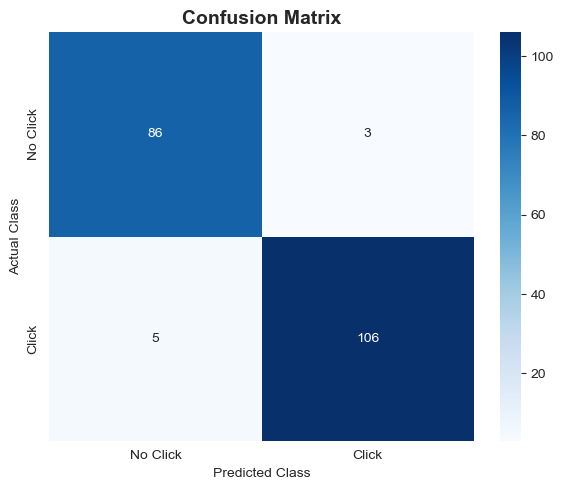

In [148]:
plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Click", "Click"],
    yticklabels=["No Click", "Click"]
)

plt.title("Confusion Matrix", fontsize=14, fontweight="bold")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()

plt.show()

---

# 10. Feature Importance 

The coefficients of the Logistic Regression model indicate the influence of each feature on the prediction. Features with larger absolute coefficient values have a greater impact on the model's decision.

In [149]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_[0]
})

importance = importance.sort_values(
    by="Coefficient",
    key=abs,
    ascending=False
)

importance

,Feature,Coefficient
3,Daily Internet Usage,-2.70
0,Daily Time Spent on Site,-2.53
2,Area Income,-1.63
1,Age,1.26
4,Male,-0.36


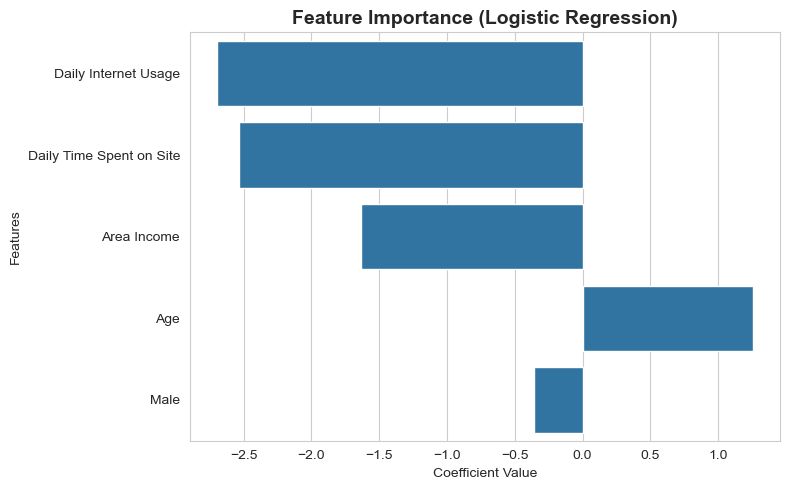

In [150]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=importance,
    x="Coefficient",
    y="Feature"
)

plt.title("Feature Importance (Logistic Regression)", fontsize=14, fontweight="bold")
plt.xlabel("Coefficient Value")
plt.ylabel("Features")

plt.tight_layout()

plt.show()

---

# Key Findings

• The Logistic Regression model achieved an overall accuracy of **96%**.

• Precision (97.25%) indicates that most predicted advertisement clicks were correct.

• Recall (95.50%) shows that the model successfully identified the majority of users who actually clicked advertisements.

• The F1 Score of 96.36% demonstrates a balanced performance between Precision and Recall.

• Daily Internet Usage and Daily Time Spent on Site were among the strongest predictors of advertisement click behaviour.

• Gender exhibited minimal influence on advertisement click prediction.

---

# Final Conclusion 

The objective of this project was to develop a Logistic Regression model capable of predicting whether a user would click on an advertisement based on demographic and behavioural attributes. After performing data exploration, visualization, feature selection, feature scaling, model training, and evaluation, the model achieved an overall accuracy of 96%, with high Precision, Recall, and F1-Score. These results indicate that the model performs consistently across both classes and generalizes well to unseen data. The analysis further revealed that user behavioural factors, such as Daily Internet Usage and Daily Time Spent on Site, had a greater influence on advertisement click behaviour than demographic variables like gender. Overall, the Logistic Regression model proved to be an effective and interpretable solution for predicting advertisement engagement and can assist organizations in making data-driven marketing decisions.

---

## Business Recommendations

• Focus marketing campaigns on behavioural indicators such as user engagement and internet usage.

• Use predictive models to identify customers with a higher probability of clicking advertisements.

• Continuously retrain the model with new customer data to maintain prediction accuracy.

• Consider incorporating additional behavioural and demographic variables to further improve model performance.

• Use the model as a decision-support tool for targeted digital advertising and customer segmentation.

---

# Learning Outcomes

Through this project, I gained practical experience in applying the complete machine learning workflow using Python. I learned how to perform data preprocessing, exploratory data analysis, feature selection, feature scaling, model training, and performance evaluation using Logistic Regression.

In addition to the technical implementation, I developed an understanding of how predictive analytics can support business decision-making by identifying customer behaviour patterns and improving targeted marketing strategies.